# 05 · Autoencoder de eliminación de ruido (DAE) en Fashion-MNIST

**Curso:** Fundamentos de Programación para la Inteligencia Artificial · **Autor:** William Lu Bjornestad

---

Primer cuaderno de **aprendizaje no supervisado**. Un *autoencoder* aprende a comprimir cada imagen en un vector de pocas dimensiones (el **espacio latente**) y a reconstruirla a partir de él. La versión de eliminación de ruido (*denoising autoencoder*, DAE) recibe la imagen con ruido y debe devolver la versión limpia. Ninguna de las dos variantes usa etiquetas.

**Objetivos**

- Entender el fundamento probabilístico del DAE (estimador MMSE y fórmula de Tweedie).
- Entrenar un DAE con espacio latente de 8 dimensiones y compararlo con un autoencoder estándar.
- Analizar el espacio latente: visualización (PCA, t-SNE) y utilidad para clasificar.

**Conceptos de pipeline de ML introducidos**

| Etapa | Qué se ve en este cuaderno |
|---|---|
| Corrupción dinámica de datos | El ruido se genera de nuevo en cada lote (como un aumento de datos) |
| Evaluación determinista | Ruido fijo con semilla para validación y test |
| Líneas base | Comparar con "no hacer nada" y con un modelo sin ruido |
| Aprendizaje de representaciones | El codificador como extractor de características |
| `sklearn.pipeline.Pipeline` | Escalado + reducción + KNN encadenados en un único estimador |

In [1]:
import copy
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import datasets
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
torch.manual_seed(SEED)
DATA_DIR = "../data"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

Dispositivo: cuda


## 1. Fundamento teórico

### Autoencoders y espacio latente

Un autoencoder se compone de un **codificador** $z = e_\phi(x)$, que reduce la imagen a un vector $z \in \mathbb{R}^d$ con $d$ pequeño, y un **decodificador** $\hat x = d_\theta(z)$, que la reconstruye. Como $z$ es un cuello de botella, la red se ve obligada a conservar solo los rasgos más informativos. La dimensión $d$ controla el compromiso: con muy pocas dimensiones la reconstrucción pierde detalles; con demasiadas, la red puede limitarse a copiar la entrada.

Una forma útil de verlo es la **hipótesis de la variedad** (*manifold hypothesis*). Las imágenes de $28 \times 28$ que parecen prendas ocupan una región minúscula y de baja dimensión (una variedad) dentro del espacio de todas las imágenes posibles. Añadir ruido gaussiano **aleja** la imagen de esa variedad, y el DAE aprende a devolverla a ella.

### El DAE desde el punto de vista bayesiano

- **Distribución a priori** $p(x)$: la distribución (desconocida) de imágenes limpias de Fashion-MNIST.
- **Verosimilitud** $p(\tilde x \mid x) = \mathcal{N}(\tilde x;\ x,\ \sigma^2 I)$: cómo el ruido genera la observación $\tilde x$ a partir de la imagen limpia $x$.
- **Distribución a posteriori** $p(x \mid \tilde x) \propto p(\tilde x \mid x)\,p(x)$: qué imágenes limpias son compatibles con la observación ruidosa.

Entrenar con error cuadrático medio, $\min_\theta \mathbb{E}\,\lVert f_\theta(\tilde x) - x \rVert^2$, tiene una solución conocida: el **estimador MMSE**, que es la media de la distribución a posteriori, $f^*(\tilde x) = \mathbb{E}[x \mid \tilde x]$. El DAE aprende, por tanto, a estimar el valor esperado de la imagen limpia dada la ruidosa, sin haber visto nunca $p(x)$ de forma explícita.

### Fórmula de Tweedie y función de puntuación

Para ruido gaussiano, la **fórmula de Tweedie** conecta esa media a posteriori con la distribución de los datos ruidosos, $p_\sigma(\tilde x)$:

$$\mathbb{E}[x \mid \tilde x] = \tilde x + \sigma^2\, \nabla_{\tilde x} \log p_\sigma(\tilde x)$$

El gradiente $\nabla \log p_\sigma$ es la **función de puntuación** (*score function*): un campo vectorial que en cada punto señala la dirección en la que la densidad de datos crece más rápido. El DAE óptimo da un paso de tamaño $\sigma^2$ en esa dirección, así que su residuo $f(\tilde x) - \tilde x$ es un estimador de la puntuación. Esta idea es la base de los **modelos de difusión** modernos, que generan imágenes encadenando muchos pasos de eliminación de ruido.

> En este cuaderno las imágenes ruidosas se recortan a $[0, 1]$ para que sigan siendo imágenes válidas. Eso rompe ligeramente la hipótesis de ruido gaussiano puro, así que la fórmula se cumple solo de forma aproximada.

La figura siguiente ilustra la fórmula en 2D con una mezcla de dos gaussianas, cuya puntuación se puede calcular exactamente con `autograd`. Las flechas grises son el campo $\nabla \log p_\sigma$. Cada punto rojo es una muestra ruidosa, y su flecha negra es el paso de Tweedie hacia la estimación MMSE.

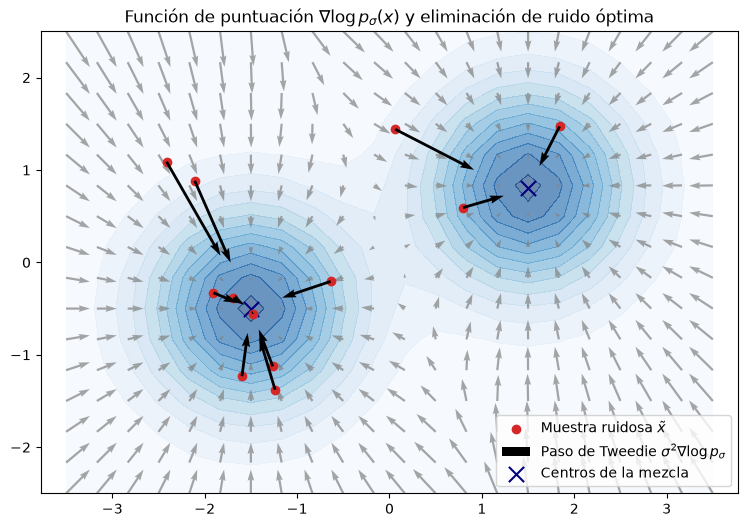

In [2]:
MIX_MEANS = torch.tensor([[-1.5, -0.5], [1.5, 0.8]])
MIX_STD, TOY_SIGMA = 0.45, 0.6


def log_p_noisy(pts):
    # Mezcla de gaussianas isótropas convolucionada con ruido N(0, sigma^2): varianzas sumadas
    var = MIX_STD**2 + TOY_SIGMA**2
    sq = ((pts.unsqueeze(1) - MIX_MEANS) ** 2).sum(-1)
    return torch.logsumexp(-sq / (2 * var), dim=1)


def score(pts):
    pts = pts.clone().requires_grad_(True)
    (grad,) = torch.autograd.grad(log_p_noisy(pts).sum(), pts)
    return grad


gx, gy = torch.meshgrid(torch.linspace(-3.5, 3.5, 22), torch.linspace(-2.5, 2.5, 16), indexing="xy")
grid = torch.stack([gx.ravel(), gy.ravel()], dim=1)
field = score(grid)

gen = torch.Generator().manual_seed(SEED)
clean = MIX_MEANS[torch.randint(0, 2, (12,), generator=gen)] + MIX_STD * torch.randn(12, 2, generator=gen)
noisy = clean + TOY_SIGMA * torch.randn(12, 2, generator=gen)
denoised = noisy + TOY_SIGMA**2 * score(noisy)

plt.figure(figsize=(9, 6))
plt.contourf(gx, gy, log_p_noisy(grid).exp().reshape(gx.shape).detach(), levels=15, cmap="Blues", alpha=0.6)
plt.quiver(grid[:, 0], grid[:, 1], field[:, 0], field[:, 1], color="grey", alpha=0.7)
plt.scatter(*noisy.T, c="tab:red", zorder=3, label=r"Muestra ruidosa $\tilde x$")
plt.quiver(noisy[:, 0], noisy[:, 1], *(denoised - noisy).T, angles="xy", scale_units="xy", scale=1,
           color="black", width=0.004, zorder=4, label=r"Paso de Tweedie $\sigma^2 \nabla \log p_\sigma$")
plt.scatter(*MIX_MEANS.T, marker="x", s=120, c="navy", label="Centros de la mezcla")
plt.title(r"Función de puntuación $\nabla \log p_\sigma(x)$ y eliminación de ruido óptima")
plt.legend(loc="lower right")
plt.axis("equal")
plt.show()

## 2. Datos

Fashion-MNIST contiene 70 000 imágenes en escala de grises de $28 \times 28$ con 10 tipos de prenda. Los tensores se toman directamente del atributo `.data` del dataset (enteros de 0 a 255) y se cargan una sola vez en la GPU. Es más rápido que recorrer el dataset imagen a imagen.

El ruido **no** se precalcula para el conjunto de entrenamiento. Se genera de nuevo en cada lote, de modo que en cada época la red ve una versión corrupta distinta de cada imagen. Si el ruido fuera fijo, la red podría acabar memorizando esas corrupciones concretas en lugar de aprender a eliminar ruido en general. Para validación y test, en cambio, el ruido se fija con una semilla para que las métricas sean deterministas y comparables.

In [3]:
def load_split(train):
    ds = datasets.FashionMNIST(DATA_DIR, train=train, download=True)
    return (ds.data.float() / 255.0).unsqueeze(1), ds.targets


x_all, y_all = load_split(train=True)
x_test, y_test = load_split(train=False)

perm = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(SEED))
val_idx, train_idx = perm[:6000], perm[6000:]
x_train, y_train = x_all[train_idx].to(device), y_all[train_idx]
x_val, y_val = x_all[val_idx].to(device), y_all[val_idx]
x_test = x_test.to(device)

NOISE_STD = 0.2


def add_noise(x, std=NOISE_STD, generator=None):
    noise = torch.randn(x.shape, generator=generator, device=x.device) * std
    return (x + noise).clamp(0, 1)


noise_gen = torch.Generator(device=device).manual_seed(SEED)
x_val_noisy = add_noise(x_val, generator=noise_gen)
x_test_noisy = add_noise(x_test, generator=noise_gen)

print(f"Entrenamiento: {len(x_train)} | validación: {len(x_val)} | test: {len(x_test)}")

Entrenamiento: 54000 | validación: 6000 | test: 10000


## 3. Modelo

El codificador reduce $784 \to 128 \to 32 \to 8$ y el decodificador invierte el camino. Decisiones de diseño:

- **LeakyReLU en lugar de ReLU.** Con ReLU, varias componentes del vector latente quedaban fijas en 0 para casi todas las entradas: son **neuronas muertas**, que desperdician parte de un espacio latente que ya es pequeño. LeakyReLU mantiene un gradiente pequeño para valores negativos y evita el problema.
- **Batch Normalization** en las capas ocultas, para estabilizar y acelerar el entrenamiento.
- **Sigmoid** en la salida, porque los píxeles están en $[0, 1]$. `Unflatten` devuelve la forma $(1, 28, 28)$ para comparar directamente con la entrada.
- **Sin Dropout.** El propio ruido de entrada ya actúa como regularizador, con el mismo objetivo que Dropout: impedir que la red dependa de píxeles concretos. Con un modelo tan compacto, el riesgo es más bien el **subajuste** (reconstrucciones borrosas), y Dropout lo agravaría. Además, combinar Dropout y BatchNorm puede provocar discrepancias entre las estadísticas de entrenamiento e inferencia.

In [4]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=8):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128), nn.BatchNorm1d(128), nn.LeakyReLU(),
            nn.Linear(128, 32), nn.BatchNorm1d(32), nn.LeakyReLU(),
            nn.Linear(32, latent_dim), nn.LeakyReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32), nn.BatchNorm1d(32), nn.LeakyReLU(),
            nn.Linear(32, 128), nn.BatchNorm1d(128), nn.LeakyReLU(),
            nn.Linear(128, 28 * 28), nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28)),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

## 4. Entrenamiento

El bucle recibe una función opcional `corrupt` que se aplica **solo en entrenamiento**, antes de pasar el lote al modelo. La pérdida siempre compara la salida con la imagen **limpia**: esa es la diferencia esencial entre un DAE y un autoencoder normal.

Hiperparámetros:

- **Pérdida MSE**: es la natural para comparar imágenes píxel a píxel y es la que justifica la interpretación MMSE de la sección 1.
- **Adam con tasa $10^{-3}$**: estable con LeakyReLU y BatchNorm.
- **Lotes de 128** y **40 épocas**: en pruebas previas la pérdida apenas mejoraba a partir de la época 40-50. Como en cuadernos anteriores, se conservan los pesos con menor pérdida de validación.

In [5]:
class GPUBatchLoader:
    def __init__(self, inputs, targets, batch_size, shuffle=False):
        self.inputs, self.targets, self.batch_size, self.shuffle = inputs, targets, batch_size, shuffle

    def __iter__(self):
        n = len(self.inputs)
        idx = torch.randperm(n, device=self.inputs.device) if self.shuffle else torch.arange(n, device=self.inputs.device)
        for i in range(0, n, self.batch_size):
            batch = idx[i:i + self.batch_size]
            yield self.inputs[batch], self.targets[batch]


def run_epoch(model, loader, loss_fn, optimizer=None, corrupt=None):
    training = optimizer is not None
    model.train(training)
    total, n = 0.0, 0
    with torch.set_grad_enabled(training):
        for x_in, x_target in loader:
            if training and corrupt is not None:
                x_in = corrupt(x_in)
            loss = loss_fn(model(x_in), x_target)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(x_in)
            n += len(x_in)
    return total / n


def fit(model, train_loader, val_loader, epochs=40, lr=1e-3, corrupt=None):
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train": [], "val": []}
    best_val, best_state = float("inf"), None
    start = time.time()
    for epoch in range(1, epochs + 1):
        history["train"].append(run_epoch(model, train_loader, loss_fn, optimizer, corrupt))
        history["val"].append(run_epoch(model, val_loader, loss_fn))
        if history["val"][-1] < best_val:
            best_val, best_state = history["val"][-1], copy.deepcopy(model.state_dict())
        if epoch == 1 or epoch % 10 == 0:
            print(f"Época {epoch:>3} | train {history['train'][-1]:.5f} | val {history['val'][-1]:.5f}")
    model.load_state_dict(best_state)
    print(f"Mejor val: {best_val:.5f} | tiempo {time.time() - start:.1f} s")
    return history


BATCH_SIZE = 128
train_loader = GPUBatchLoader(x_train, x_train, BATCH_SIZE, shuffle=True)

torch.manual_seed(SEED)
dae = Autoencoder(latent_dim=8).to(device)
hist_dae = fit(dae, train_loader, GPUBatchLoader(x_val_noisy, x_val, 1024), corrupt=add_noise)

Época   1 | train 0.03668 | val 0.02378


Época  10 | train 0.01702 | val 0.01652


Época  20 | train 0.01601 | val 0.01548


Época  30 | train 0.01563 | val 0.01506


Época  40 | train 0.01538 | val 0.01495
Mejor val: 0.01487 | tiempo 181.0 s


Como **línea base** se entrena también un autoencoder estándar, con la misma arquitectura y el mismo presupuesto, pero sin ruido: su entrada y su objetivo son la imagen limpia.

Época   1 | train 0.03694 | val 0.02334


Época  10 | train 0.01630 | val 0.01581


Época  20 | train 0.01529 | val 0.01483


Época  30 | train 0.01490 | val 0.01446


Época  40 | train 0.01461 | val 0.01419
Mejor val: 0.01419 | tiempo 95.7 s


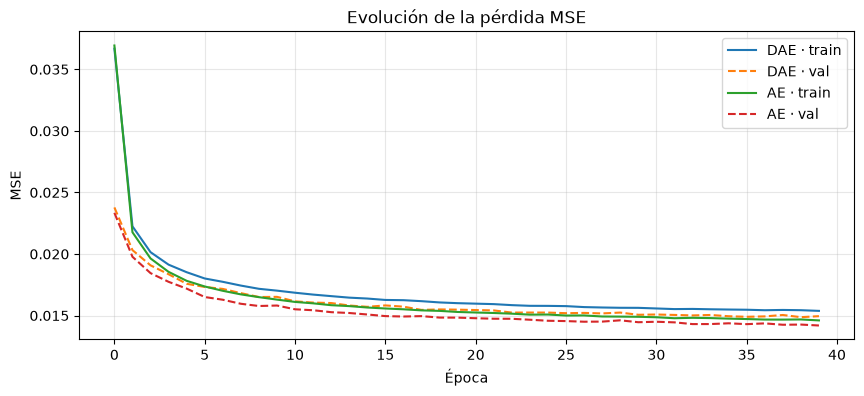

In [6]:
torch.manual_seed(SEED)
ae = Autoencoder(latent_dim=8).to(device)
hist_ae = fit(ae, train_loader, GPUBatchLoader(x_val, x_val, 1024), corrupt=None)

plt.figure(figsize=(10, 4))
plt.plot(hist_dae["train"], label="DAE · train")
plt.plot(hist_dae["val"], label="DAE · val", linestyle="--")
plt.plot(hist_ae["train"], label="AE · train")
plt.plot(hist_ae["val"], label="AE · val", linestyle="--")
plt.title("Evolución de la pérdida MSE")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. Evaluación en test

Se evalúan ambos modelos con entradas limpias y con entradas ruidosas (ruido fijo), y se incluye la referencia de **no hacer nada**, es decir, comparar la imagen ruidosa directamente con la limpia. Un DAE solo es útil si mejora claramente esa referencia.

In [7]:
def reconstruct(model, x, batch_size=1024):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x[i:i + batch_size]) for i in range(0, len(x), batch_size)])


def image_metrics(pred, target):
    mse = ((pred - target) ** 2).mean().item()
    return {"MSE": mse, "MAE": (pred - target).abs().mean().item(), "PSNR (dB)": 10 * np.log10(1 / mse)}


rows = {"Sin modelo (entrada ruidosa)": image_metrics(x_test_noisy, x_test)}
for name, model in [("AE", ae), ("DAE", dae)]:
    rows[f"{name} · entrada limpia"] = image_metrics(reconstruct(model, x_test), x_test)
    rows[f"{name} · entrada ruidosa"] = image_metrics(reconstruct(model, x_test_noisy), x_test)
pd.DataFrame(rows).T.round(4)

,MSE,MAE,PSNR (dB)
Sin modelo (entrada ruidosa),0.0255,0.1089,15.9317
AE · entrada limpia,0.0141,0.0625,18.5026
AE · entrada ruidosa,0.0203,0.0848,16.9180
DAE · entrada limpia,0.0170,0.0669,17.7040
DAE · entrada ruidosa,0.0148,0.0645,18.2946


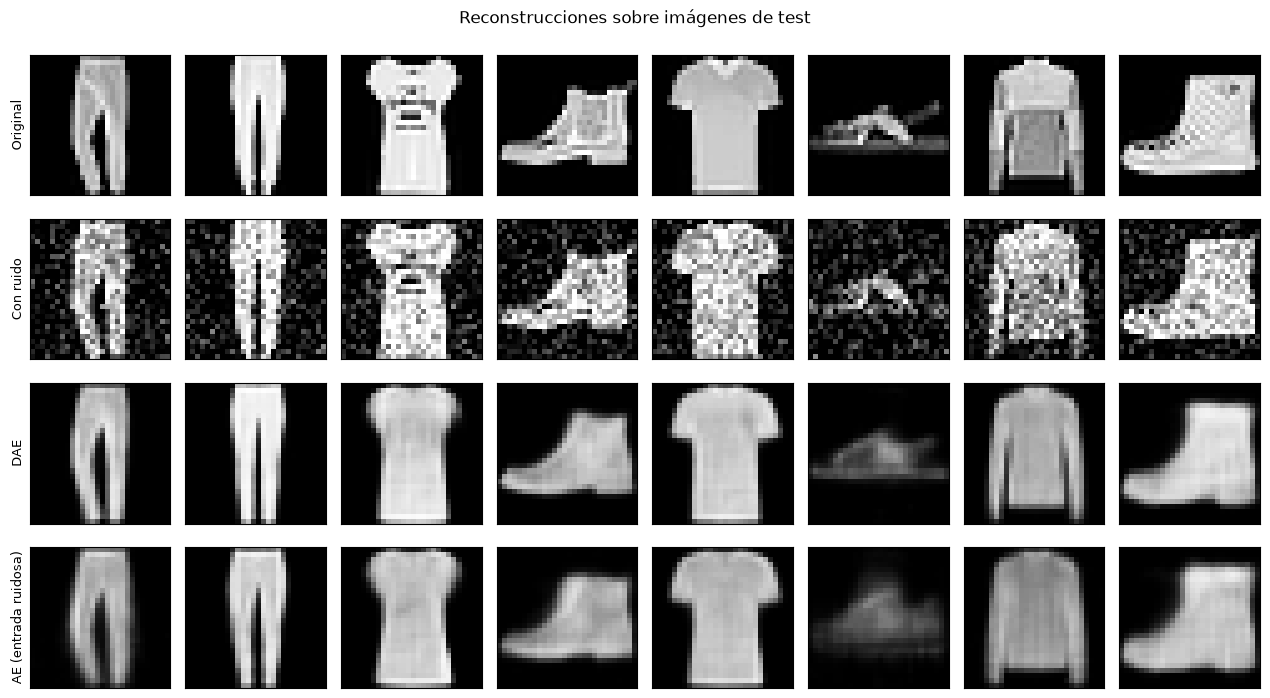

In [8]:
n_show = 8
idx = torch.randperm(len(x_test), generator=torch.Generator().manual_seed(1))[:n_show]
rows_img = [
    ("Original", x_test[idx]),
    ("Con ruido", x_test_noisy[idx]),
    ("DAE", reconstruct(dae, x_test_noisy[idx])),
    ("AE (entrada ruidosa)", reconstruct(ae, x_test_noisy[idx])),
]
fig, axes = plt.subplots(len(rows_img), n_show, figsize=(1.6 * n_show, 1.8 * len(rows_img)))
for r, (title, imgs) in enumerate(rows_img):
    for c in range(n_show):
        axes[r, c].imshow(imgs[c].squeeze().cpu(), cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(title, fontsize=9)
plt.suptitle("Reconstrucciones sobre imágenes de test")
plt.tight_layout()
plt.show()

### Lectura de los resultados

- **El ruido perjudica al AE estándar.** Su PSNR cae más de 1.5 dB al pasar de entradas limpias a ruidosas, y con ruido apenas mejora la referencia de "no hacer nada". El cuello de botella de 8 dimensiones descarta parte del ruido por sí solo, pero no basta.
- **El DAE con entrada ruidosa casi iguala al AE con entrada limpia.** Ha aprendido a proyectar la imagen corrupta de vuelta a la variedad de las prendas, que era el objetivo.
- **Un resultado llamativo: el DAE funciona peor con imágenes limpias que con ruidosas.** Nunca vio imágenes limpias durante el entrenamiento, así que para él son entradas **fuera de distribución**: tienen otras estadísticas de píxel, y las capas de BatchNorm normalizan con medias y varianzas calculadas sobre datos ruidosos. Es un ejemplo pequeño de un problema muy general en producción: un modelo rinde mejor en las condiciones en las que se entrenó, y conviene que el entrenamiento cubra todas las condiciones de uso (aquí bastaría con entrenar con varios niveles de ruido, incluido el cero).
- Las reconstrucciones son **borrosas**. Es lo esperado de un estimador MMSE: cuando varias imágenes limpias son compatibles con la entrada, la media a posteriori las promedia. Un espacio latente de 8 dimensiones además limita el detalle que se puede conservar, así que texturas, estampados y las tiras de las sandalias se pierden.

## 6. El espacio latente

Se codifican las imágenes **limpias** de test y se visualizan pares de dimensiones del vector latente, coloreadas por clase. El modelo nunca ha visto las etiquetas: cualquier agrupación por clase ha surgido solo del objetivo de reconstrucción.

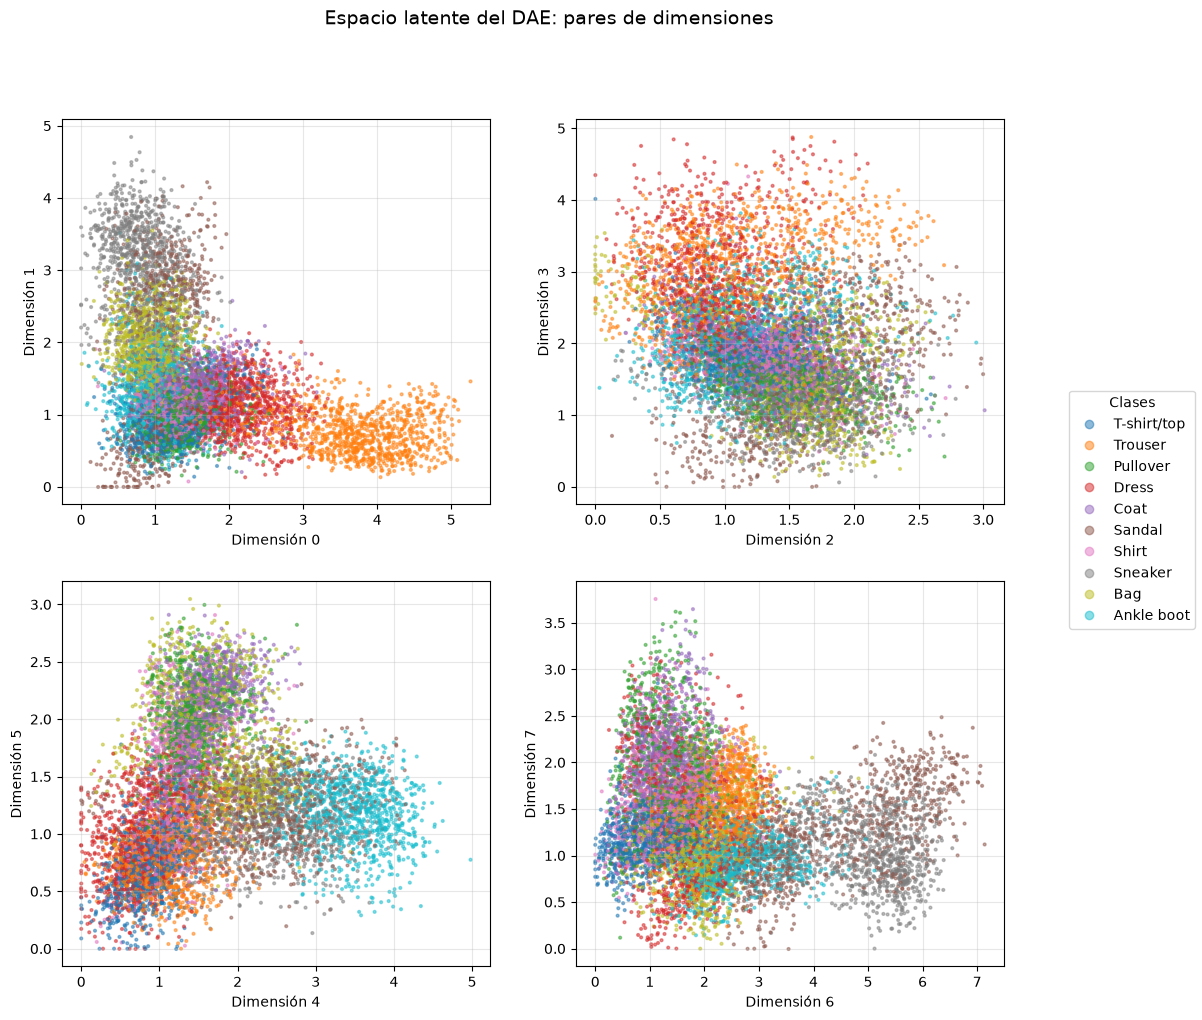

In [9]:
def encode(model, x, batch_size=1024):
    model.eval()
    with torch.no_grad():
        return torch.cat([model.encoder(x[i:i + batch_size]) for i in range(0, len(x), batch_size)]).cpu().numpy()


z_test = encode(dae, x_test)
y_test_np = y_test.numpy()

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for i, ax in enumerate(axes.flat):
    sc = ax.scatter(z_test[:, 2 * i], z_test[:, 2 * i + 1], c=y_test_np, cmap="tab10", s=4, alpha=0.5)
    ax.set_xlabel(f"Dimensión {2 * i}")
    ax.set_ylabel(f"Dimensión {2 * i + 1}")
    ax.grid(True, alpha=0.3)
fig.legend(sc.legend_elements()[0], CLASSES, title="Clases", loc="center right")
fig.suptitle("Espacio latente del DAE: pares de dimensiones", fontsize=14)
plt.subplots_adjust(right=0.85)
plt.show()

### Reducción de dimensiones para visualizar

Ver pares de dimensiones sueltas muestra solo proyecciones parciales. Para ver las 8 dimensiones a la vez se proyectan a 2D con dos técnicas complementarias:

- **PCA** busca las direcciones lineales de máxima varianza. Es rápida y conserva la estructura global, pero como es una proyección **lineal**, clases separadas por fronteras no lineales se solapan.
- **t-SNE** busca una disposición en 2D en la que los **vecinos cercanos** del espacio original sigan siéndolo. El parámetro `perplexity` fija aproximadamente cuántos vecinos se consideran. t-SNE no conserva distancias globales: el tamaño de los grupos y la distancia entre ellos en la figura no tienen significado directo. `init="pca"` solo usa PCA como punto de partida de la optimización, lo que da resultados más estables.

Varianza explicada por PC1 y PC2: [47.67 21.01] %


t-SNE: 34.3 s


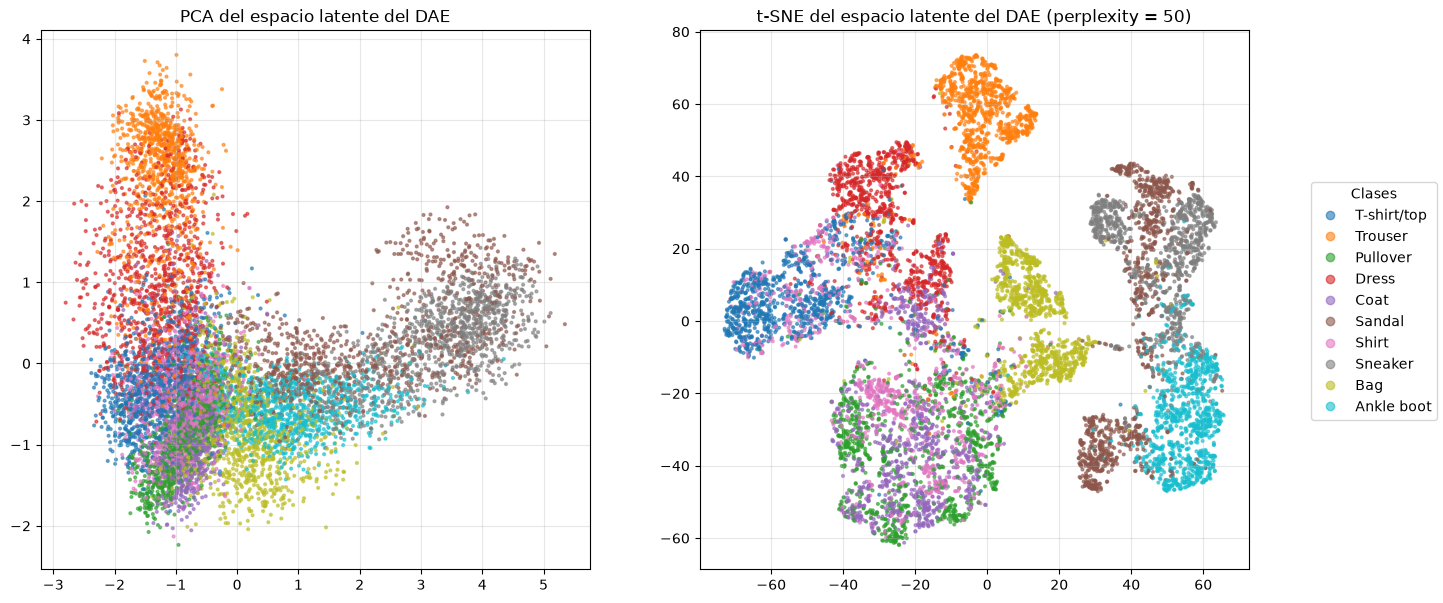

In [10]:
def plot_embedding(emb, title, ax):
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=y_test_np, cmap="tab10", s=4, alpha=0.6)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    return sc


pca = PCA(n_components=2).fit(z_test)
z_pca = pca.transform(z_test)
print("Varianza explicada por PC1 y PC2:", (pca.explained_variance_ratio_ * 100).round(2), "%")

start = time.time()
z_tsne = TSNE(n_components=2, perplexity=50, init="pca", learning_rate="auto", random_state=SEED).fit_transform(z_test)
print(f"t-SNE: {time.time() - start:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_embedding(z_pca, "PCA del espacio latente del DAE", axes[0])
sc = plot_embedding(z_tsne, "t-SNE del espacio latente del DAE (perplexity = 50)", axes[1])
fig.legend(sc.legend_elements()[0], CLASSES, title="Clases", loc="center right")
plt.subplots_adjust(right=0.88)
plt.show()

## 7. El espacio latente como características: pipeline con KNN

En t-SNE, pantalones, bolsos y calzado forman grupos bien separados, e incluso las sandalias se dividen en dos subgrupos (probablemente estilos distintos). En cambio, *Pullover*, *Coat* y *Shirt*, prendas de parte superior con siluetas muy parecidas, se mezclan. Para **medir** la calidad de estos grupos, se usa el codificador como extractor de características y se entrena un clasificador *k*-vecinos más cercanos (KNN) sobre los vectores latentes. La exactitud del KNN resume en un número la calidad de la representación: si imágenes de la misma clase están cerca en el espacio latente, el KNN acierta.

Cada alternativa se construye como un `Pipeline` de scikit-learn. El escalado (y la reducción, cuando la hay) se ajusta con los datos de entrenamiento y se aplica automáticamente al predecir, con la misma lógica *fit/transform* del cuaderno 01. Se comparan cuatro representaciones:

| Representación | Dimensión | Pipeline |
|---|---|---|
| Píxeles | 784 | `StandardScaler → KNN` |
| PCA de píxeles | 8 | `StandardScaler → PCA(8) → KNN` |
| Latente del AE | 8 | `StandardScaler → KNN` |
| Latente del DAE | 8 | `StandardScaler → KNN` |

Las etiquetas **solo** se usan en esta sección, para evaluar. Los autoencoders se entrenaron sin ellas.

In [11]:
def knn_pipeline(*steps):
    return make_pipeline(StandardScaler(), *steps, KNeighborsClassifier(n_neighbors=5))


pixels_train = x_train.flatten(1).cpu().numpy()
pixels_test = x_test.flatten(1).cpu().numpy()
feature_sets = {
    "Píxeles (784)": (knn_pipeline(), pixels_train, pixels_test),
    "PCA de píxeles (8)": (knn_pipeline(PCA(n_components=8, random_state=SEED)), pixels_train, pixels_test),
    "Latente AE (8)": (knn_pipeline(), encode(ae, x_train), encode(ae, x_test)),
    "Latente DAE (8)": (knn_pipeline(), encode(dae, x_train), encode(dae, x_test)),
}

knn_results = {}
for name, (pipe, f_train, f_test) in feature_sets.items():
    start = time.time()
    pipe.fit(f_train, y_train.numpy())
    knn_results[name] = {"exactitud KNN": pipe.score(f_test, y_test_np), "tiempo (s)": time.time() - start}
pd.DataFrame(knn_results).T.round(4)

,exactitud KNN,tiempo (s)
Píxeles (784),0.8509,7.4357
PCA de píxeles (8),0.7827,1.9154
Latente AE (8),0.8323,0.4509
Latente DAE (8),0.8310,0.4032


### Interpolación en el espacio latente

Si el espacio latente fuera continuo y "ordenado", recorrer la línea recta entre dos puntos produciría imágenes intermedias coherentes. Se toma el **prototipo** de dos clases (el vector latente medio de todas sus imágenes) y se decodifican puntos intermedios $z = (1 - t)\,z_A + t\,z_B$.

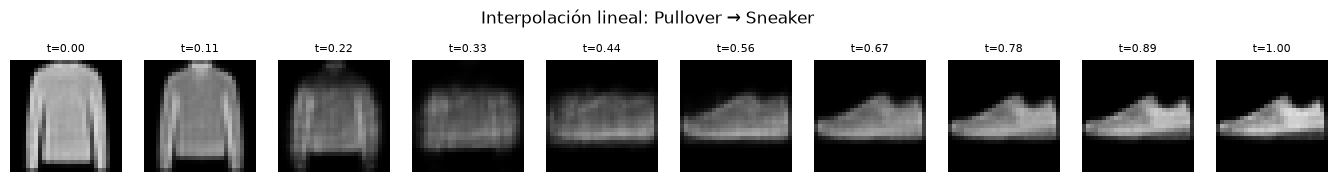

In [12]:
def interpolate(model, class_a, class_b, z, labels, steps=10):
    z_a = torch.tensor(z[labels == class_a].mean(axis=0), device=device)
    z_b = torch.tensor(z[labels == class_b].mean(axis=0), device=device)
    ts = torch.linspace(0, 1, steps, device=device).unsqueeze(1)
    model.eval()
    with torch.no_grad():
        imgs = model.decoder((1 - ts) * z_a + ts * z_b).cpu()
    fig, axes = plt.subplots(1, steps, figsize=(1.7 * steps, 2.2))
    for ax, img, t in zip(axes, imgs, ts):
        ax.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"t={t.item():.2f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Interpolación lineal: {CLASSES[class_a]} → {CLASSES[class_b]}")
    plt.show()


interpolate(dae, 2, 7, z_test, y_test_np)   # Pullover -> Sneaker

## 8. Conclusiones y limitaciones

- **Un DAE aprende la media a posteriori.** Entrenar con MSE sobre pares (ruidosa, limpia) produce, en el óptimo, el estimador MMSE, y la fórmula de Tweedie lo relaciona con la función de puntuación de los datos. Es la misma idea que, llevada al límite, da lugar a los modelos de difusión.
- **La corrupción es un aumento de datos.** Generar ruido nuevo en cada lote es barato y evita memorizar corrupciones concretas. Para evaluar, en cambio, el ruido tiene que ser fijo.
- **Las líneas base dan contexto a las métricas.** Sin la referencia de "no hacer nada" ni el AE sin ruido, un PSNR aislado no dice si el modelo es bueno.
- **Representaciones útiles sin etiquetas.** Con solo 8 dimensiones aprendidas sin supervisión (100 veces menos que los píxeles), el KNN pierde apenas un par de puntos de exactitud respecto a los 784 píxeles, supera con claridad a una compresión lineal (PCA) de la misma dimensión y es mucho más rápido. El espacio latente ha capturado buena parte de la estructura semántica del conjunto de datos. AE y DAE obtienen prácticamente la misma exactitud: el objetivo de eliminar ruido mejora la robustez, pero no la separación entre clases.
- **Los modelos rinden en las condiciones en que se entrenan.** El DAE supera al AE con entradas ruidosas pero pierde con entradas limpias: la distribución de entrenamiento debe cubrir la de uso.
- **Pero el espacio latente no está organizado para generar.** Las clases forman grupos, pero:
  - Nada obliga a que el espacio **entre** grupos corresponda a imágenes válidas. En la interpolación de *Pullover* a *Sneaker*, los pasos intermedios ($t \approx 0.3$–$0.45$) no son ninguna prenda, sino una mancha borrosa que superpone ambas siluetas.
  - Prendas intermedias (una zapatilla de caña alta, entre *Sneaker* y *Ankle boot*) acaban en uno u otro grupo sin que el modelo exprese esa ambigüedad.
  - No hay una distribución conocida de la que **muestrear** nuevos vectores latentes, así que no se pueden generar imágenes nuevas de forma fiable.

**Siguiente paso:** el cuaderno 06 resuelve estas limitaciones con un **autoencoder variacional (VAE)**, que impone una distribución conocida al espacio latente y lo convierte en un modelo generativo.